In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, auc, roc_auc_score, mutual_info_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold

from tqdm.auto import tqdm


In [2]:
url = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
df = pd.read_csv(url)
df.head().T

,0,1,2,3,4
lead_source,organic_search,social_media,referral,paid_ads,referral
industry,technology,technology,retail,manufacturing,manufacturing
employment_status,employed,employed,employed,student,student
location,europe,south_america,europe,NaN,north_america
annual_income,88160.0,72688.0,44697.0,NaN,24062.0
number_of_courses_viewed,3,3,3,3,4
interaction_count,4,7,4,6,5
lead_score,0.64,0.72,0.58,0.57,0.62
converted,1,1,1,0,1


In [3]:
df.columns = df.columns.str.lower().str.replace(' ', '_')
categorical_columns = list(df.dtypes[df.dtypes == 'str'].index)
for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')
numerical_columns = df.select_dtypes(include='number').columns.drop('converted').tolist()
all_features = categorical_columns + numerical_columns

In [4]:
df[numerical_columns] = df[numerical_columns].fillna(0)
df[categorical_columns] = df[categorical_columns].fillna('NA')

In [5]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [6]:
df_train[numerical_columns].head()


,annual_income,number_of_courses_viewed,interaction_count,lead_score
4740,80198.0,5,9,0.91
1452,50548.0,2,5,0.48
2846,76300.0,0,3,0.42
4670,80371.0,2,6,0.49
168,73567.0,2,4,0.48


Q1

In [8]:
for current_var in numerical_columns:
    auc_score = roc_auc_score(df_train['converted'], df_train[current_var])
    print(f'Variable: {current_var} auc_score: {auc_score}') 

Variable: annual_income auc_score: 0.6081977776250831
Variable: number_of_courses_viewed auc_score: 0.7229894623989618
Variable: interaction_count auc_score: 0.7649203047563227
Variable: lead_score auc_score: 0.7882254810906102


Q2

In [9]:
def train_and_predict(df_train, df_val, features, C=1.0):

    y_train = df_train['converted']
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(df_train[features].to_dict(orient='records'))
    X_val = dv.transform(df_val[features].to_dict(orient='records'))

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)
    y_pred = model.predict_proba(X_val)[:, 1]

    return y_pred
    

In [10]:
def calc_auc(df_train, df_val, C=1.0):
    y_pred = train_and_predict(df_train, df_val, all_features, C)
    auc = roc_auc_score(df_val['converted'], y_pred)
    return auc


In [11]:
auc = calc_auc(df_train, df_val)
print(auc)

0.7318222288173319


Q3

In [12]:
def confusion_table(y_pred, y_bench, tresholds):
    scores = []
    for t in thresholds:
        actual_positive = (y_bench == 1)
        actual_negative = (y_bench == 0)
    
        predict_positive = (y_pred >= t)
        predict_negative = (y_pred < t)


        tp = (predict_positive & actual_positive).sum()
        tn = (predict_negative & actual_negative).sum()


        fp = (predict_positive & actual_negative).sum()
        fn = (predict_negative & actual_positive).sum()
    
        scores.append((t, tp, fp, fn, tn))


    columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
    df_scores = pd.DataFrame(scores, columns=columns)

    df_scores['recall'] = df_scores.tp / (df_scores.tp + df_scores.fn)
    df_scores['precision'] = df_scores.tp / (df_scores.tp + df_scores.fp)

    return df_scores

 

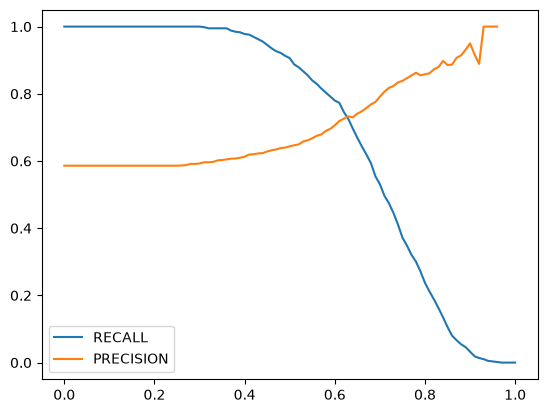

In [14]:
thresholds = np.linspace(0, 1, 101)

y_pred = train_and_predict(df_train, df_val, all_features)
df_scores = confusion_table(y_pred, df_val['converted'], thresholds)


plt.plot(df_scores.threshold, df_scores['recall'], label='RECALL')
plt.plot(df_scores.threshold, df_scores['precision'], label='PRECISION')
plt.legend()


Q4

In [15]:
thresholds = np.linspace(0, 1, 101)
y_pred = train_and_predict(df_train, df_val, all_features)

df_scores = confusion_table(y_pred, df_val['converted'], thresholds)
df_scores['F1'] = 2 * df_scores.recall * df_scores.precision / (df_scores.recall + df_scores.precision)
max_f1 = df_scores.loc[df_scores.F1.idxmax()]
print(f'Threshold {max_f1.threshold:.2f} with max F1 {max_f1.F1:.3f}')

Threshold 0.41 with max F1 0.758


Q5

In [20]:
def calc_kfold(C):
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train_ = df_full_train.iloc[train_idx]
        df_val_ = df_full_train.iloc[val_idx]

        auc_ = calc_auc(df_train_, df_val_, C=C)

        scores.append(auc_)
    return np.mean(scores), np.std(scores)

In [23]:
C = 1
mean_scores, std_scores = calc_kfold(C)
print('C=%s %.3f +- %.3f' % (C, mean_scores, std_scores))

C=1 0.732 +- 0.007


Q6

In [24]:
for C in tqdm([0.000001, 0.001, 0.1]):
    mean_scores, std_scores = calc_kfold(C)
    print('C=%s %.3f +- %.3f' % (C, mean_scores, std_scores))

  0%|          | 0/3 [00:00<?, ?it/s]

C=1e-06 0.617 +- 0.019
C=0.001 0.749 +- 0.010
C=0.1 0.732 +- 0.007
